<br>
<br>


# `#01: Anchor Boxes`


<br>
<br>

**Revise IoU(Intersection Over Union) before this.**

`Our object in object detection is to detect one object. But if one bounding boxed captured two object then how to fix it?? We can use the concept of anchor boxes.`

<br>

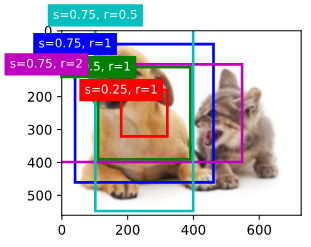

In [9]:
from IPython.display import Image,display

# One box is detect multiple object.
Image("../note/photo/image28.png")


 
    i) The output Should be like this bro.



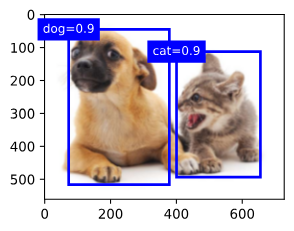

In [6]:


# The output should be like this. bro:
print(""" 
    i) The output Should be like this bro.
"""
)
Image("../note/photo/image29.png")


 

i) Here, at, first there are only one boxes that capture the man and the car. But there should be 
two bounding boxes. 

ii) To, sovle this type of problelm, first we assume there are so many anchor boxes. For the below example 
we take only two boxes.




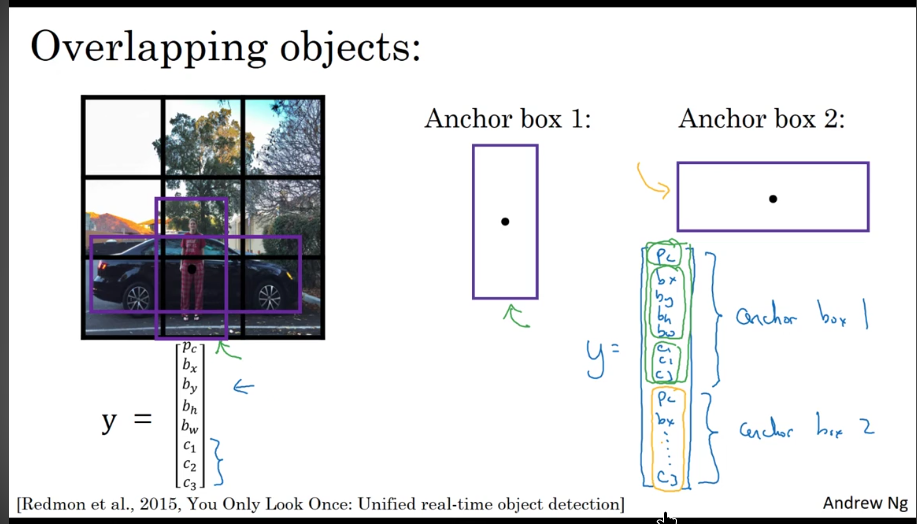



iii) In the code, for understanding, we assume that our ground truth value contains 2 face(truths) and 
we assume there are two anchor boxes.




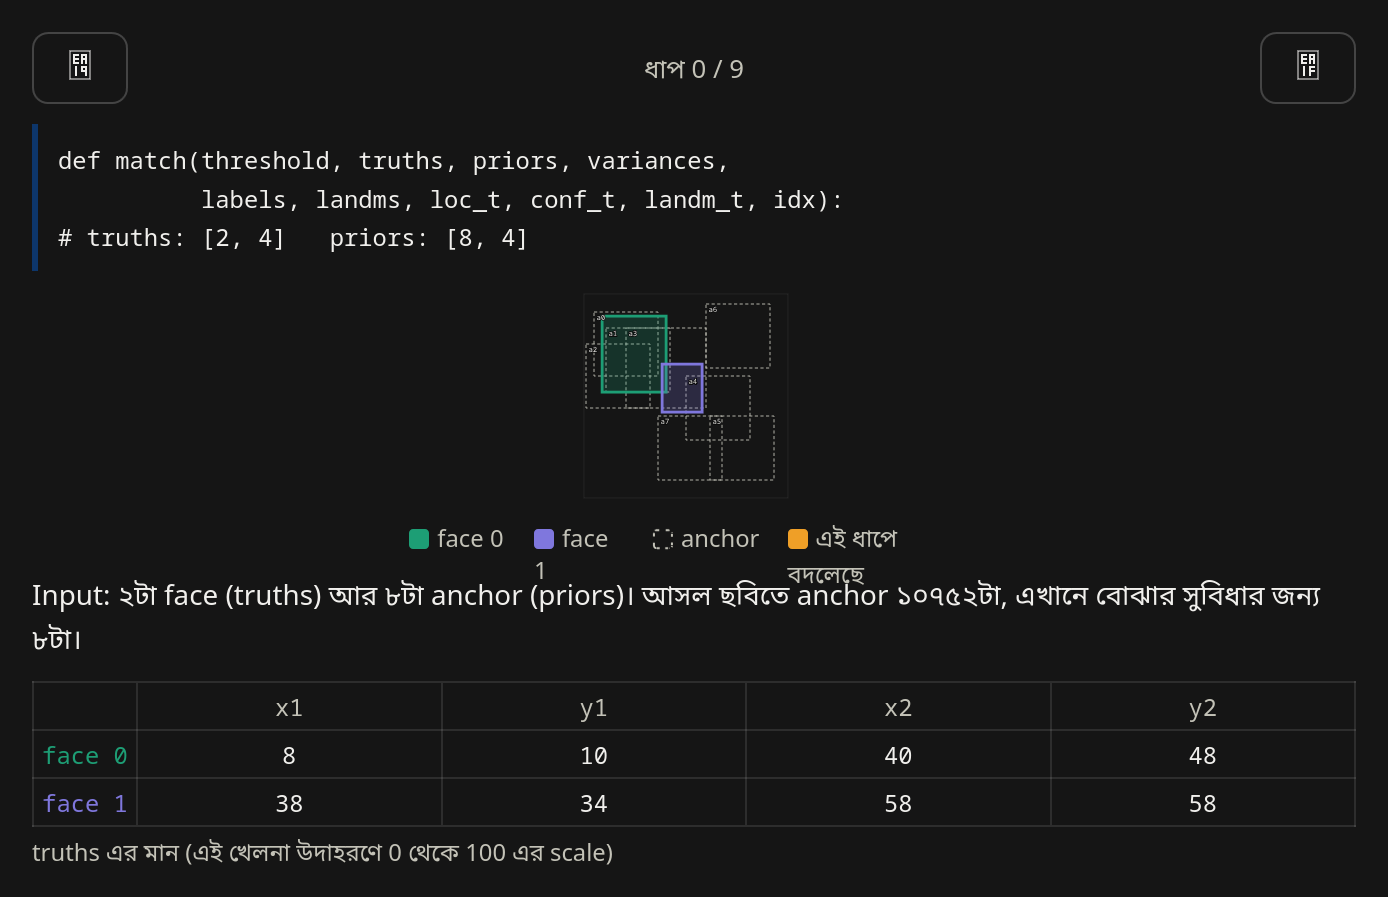



iv) Then we find which, anchor points IoU is to our truth value. IoU return a table like below.




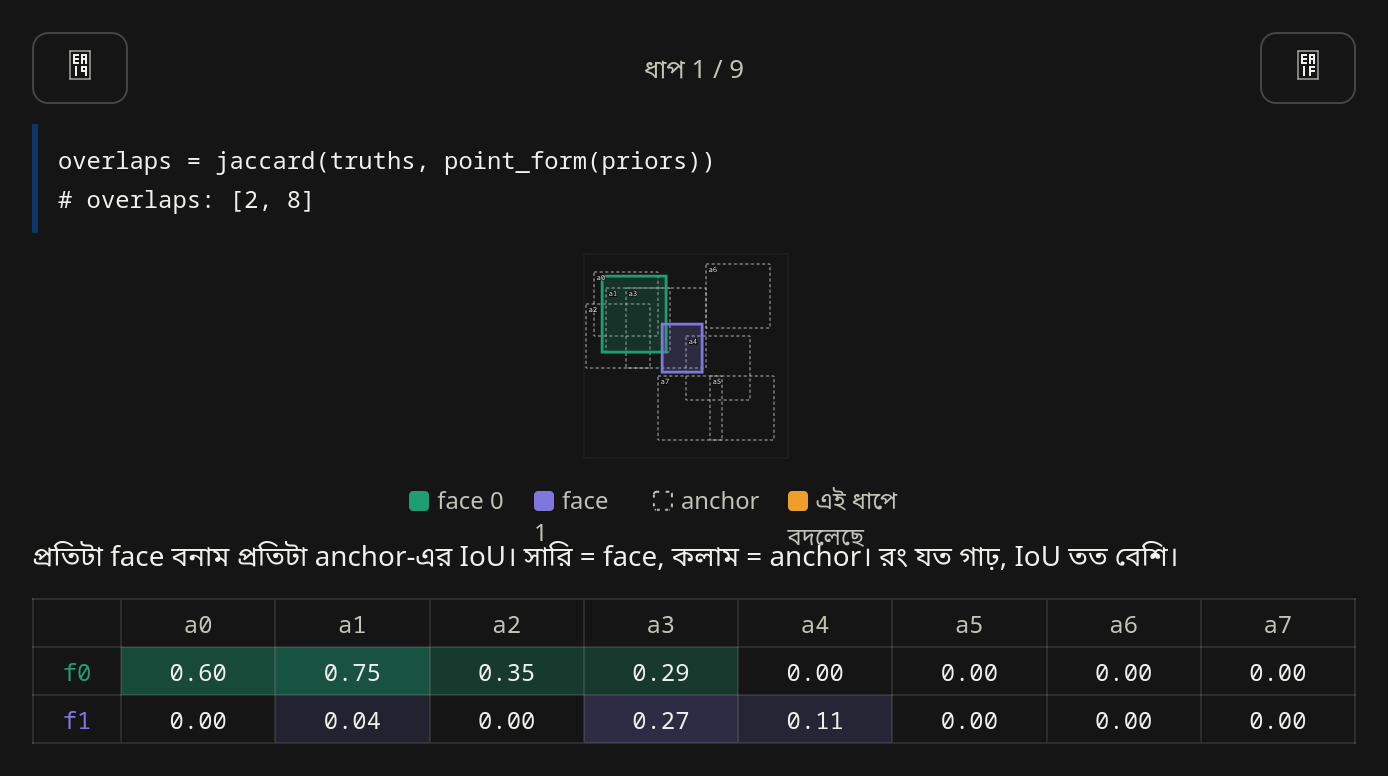



v) In, the code we do max(to find the best prior on the column.)




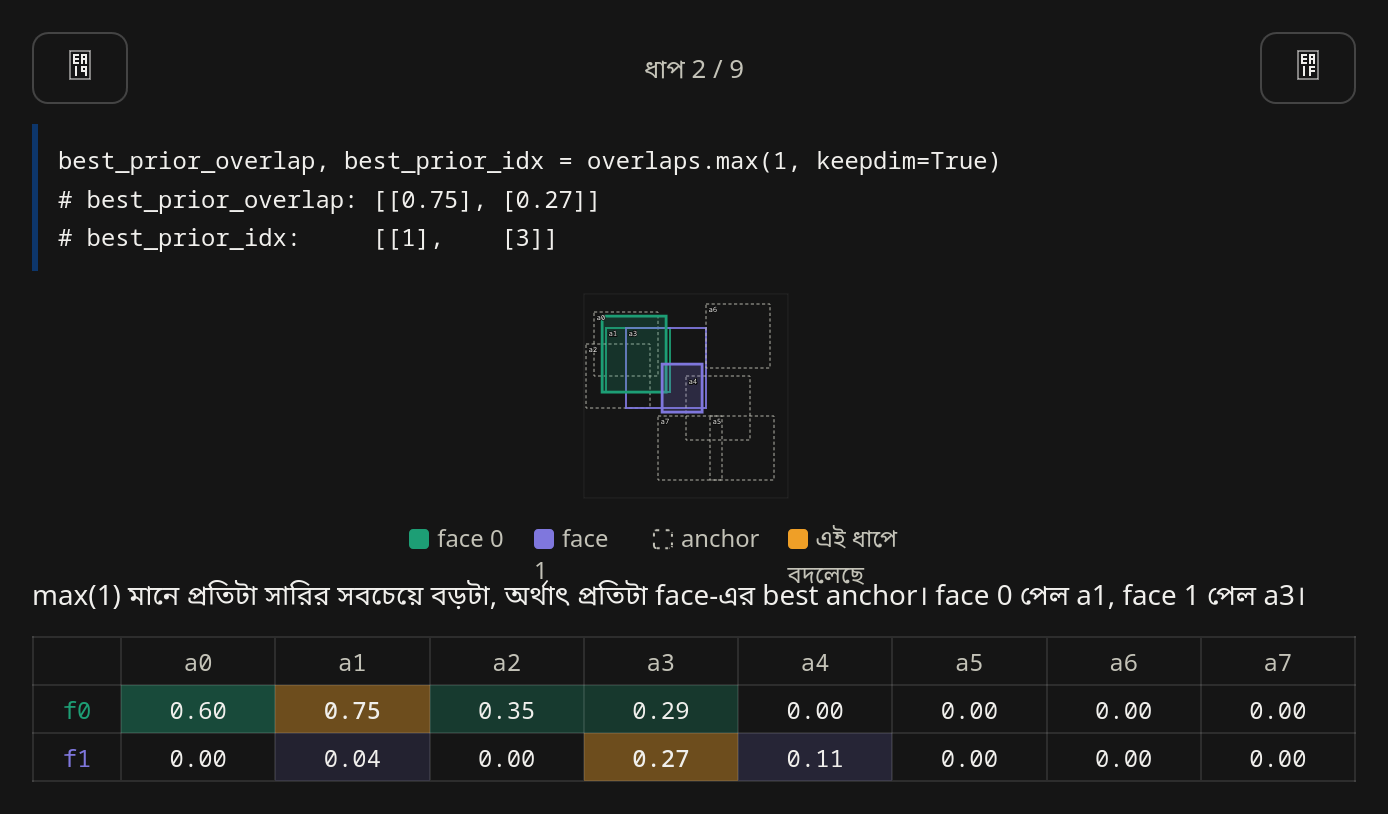



vi) There is a hard theshold, 0.2 if IoU value is less then 0.2 then the ignore them.



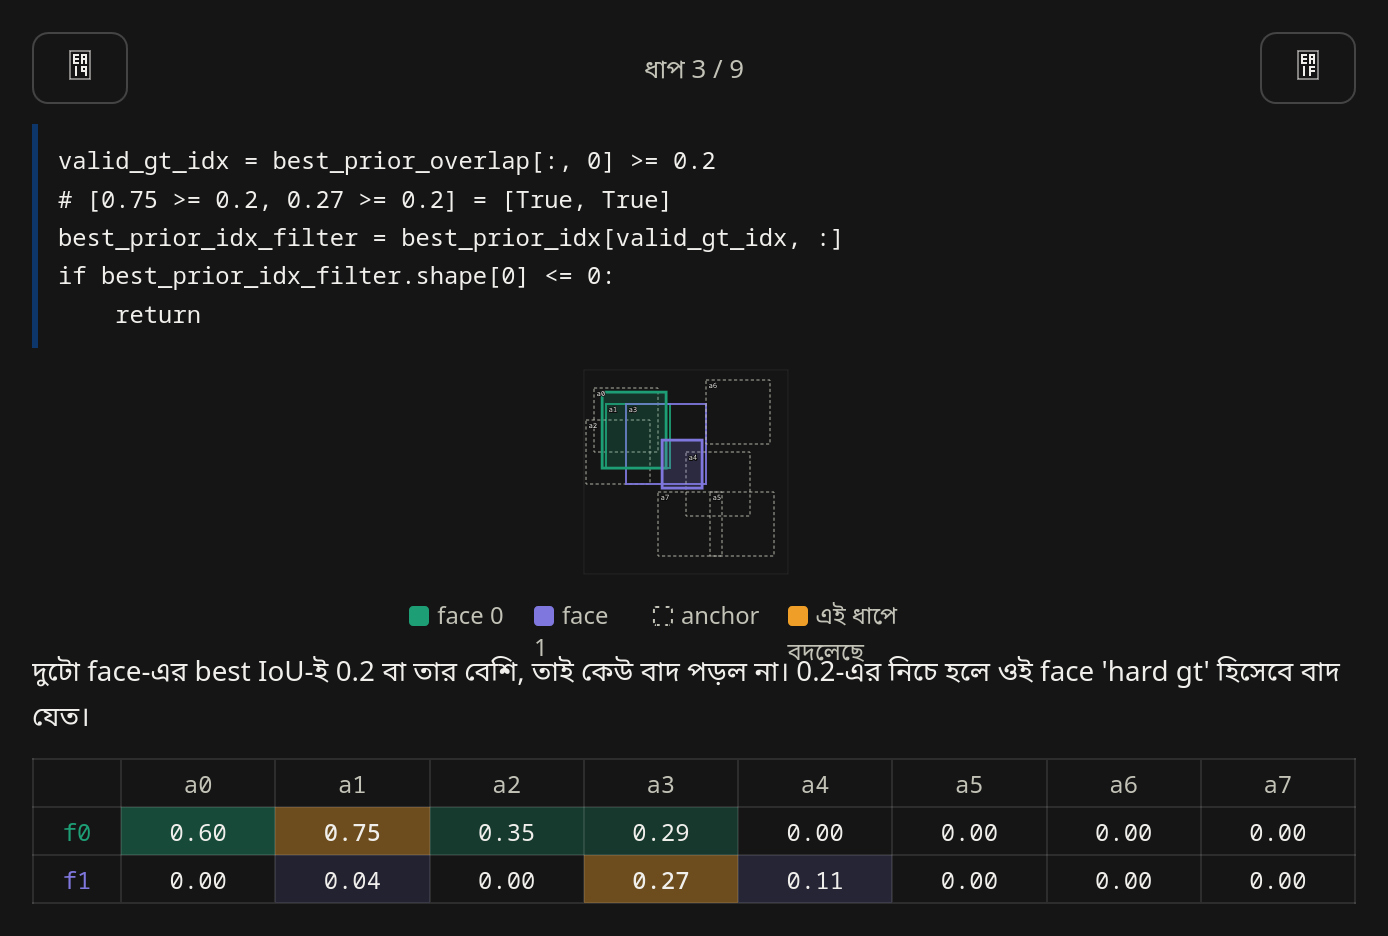



vii) Then here we find row wise max value with their indices.



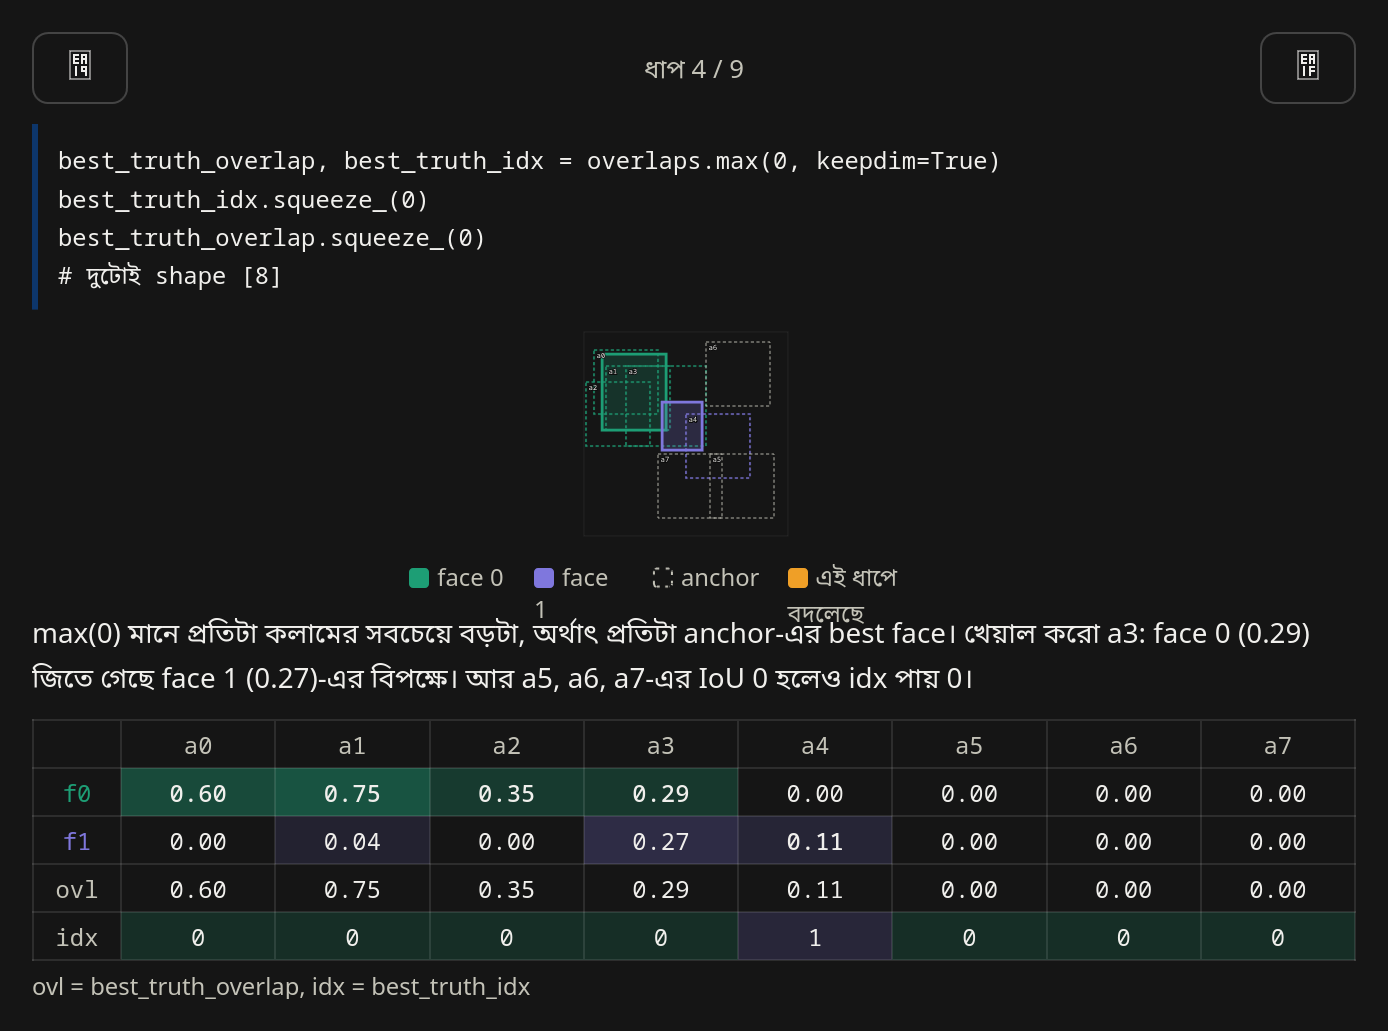



vii) Replace the value, of anchor1->index and anchor3->index:




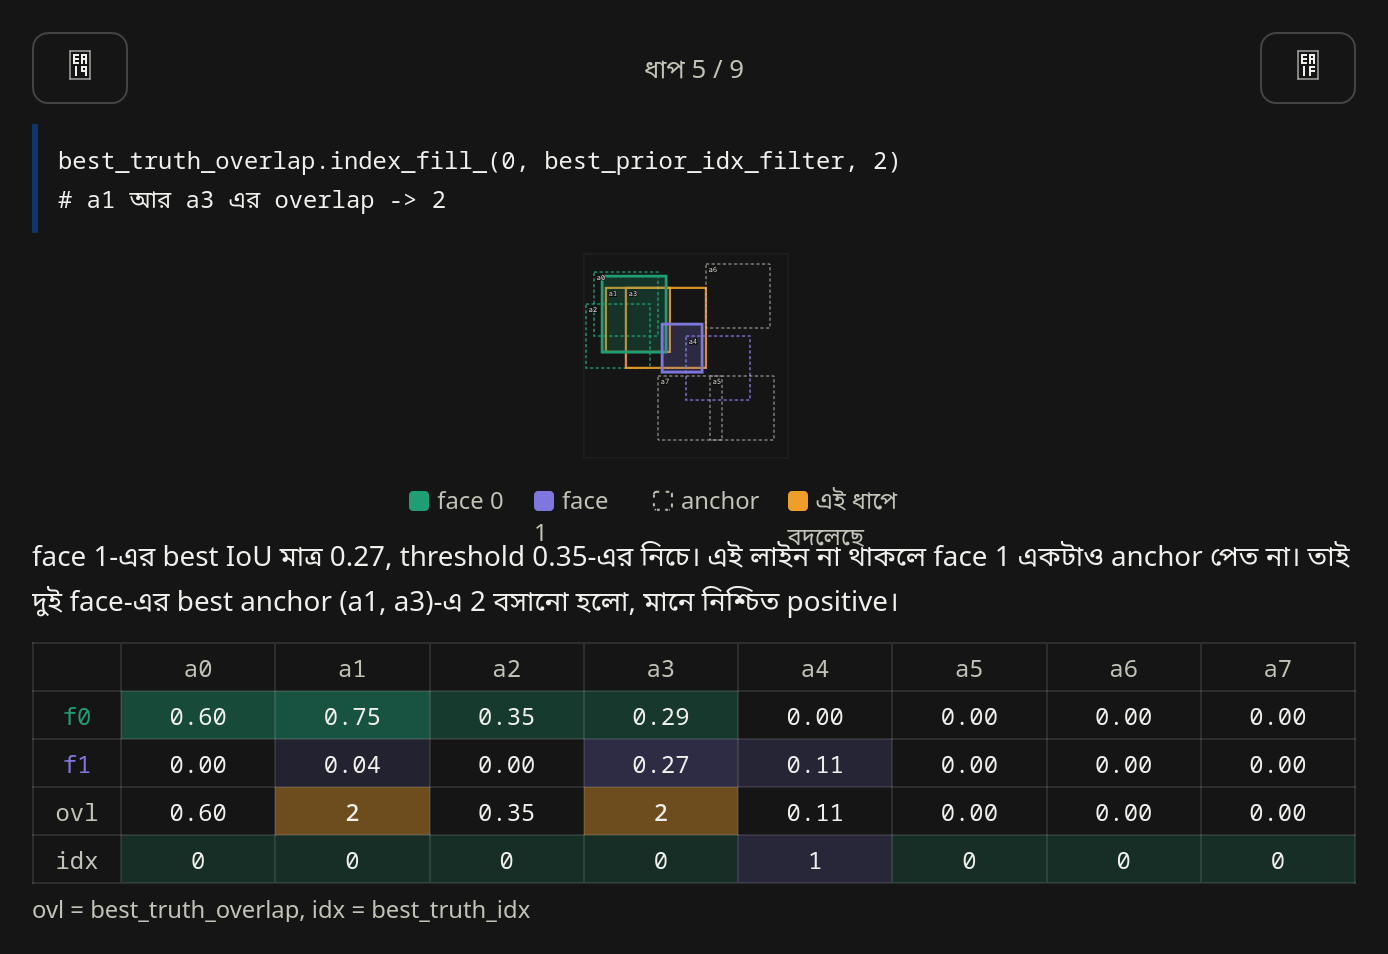



vii) While doing row wise maximum, our anchor-3 taken by the face-0. But, the prior said that
maybe it's face-1. So, our loop modify this. 




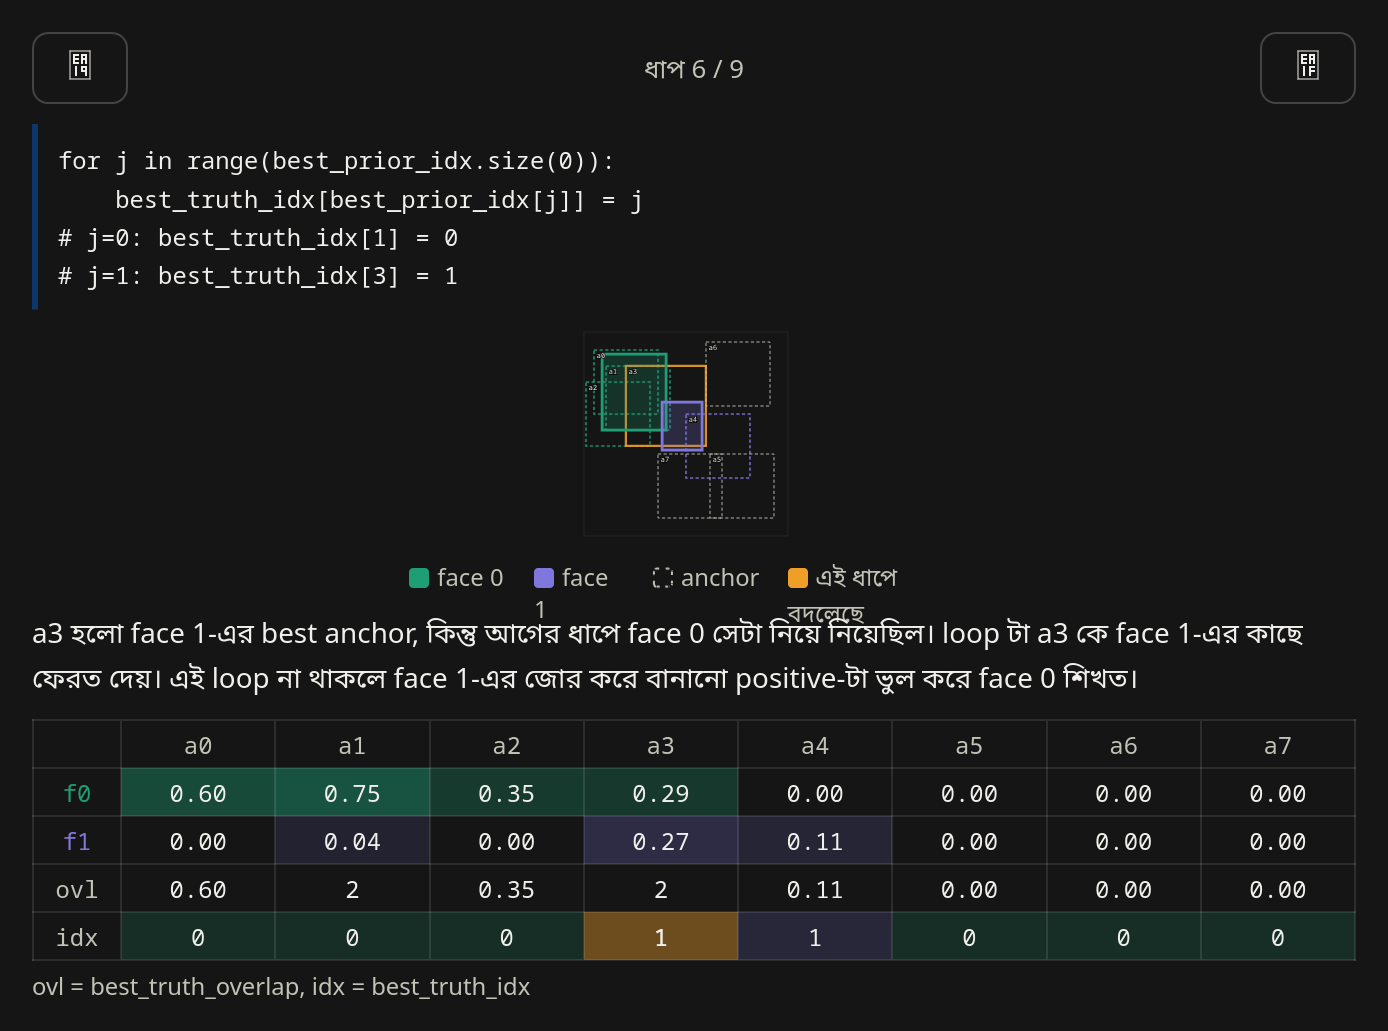



viii) Now, based on our theshold, we find the confidance score. if confidence<0.35, 
then, mark it background. 




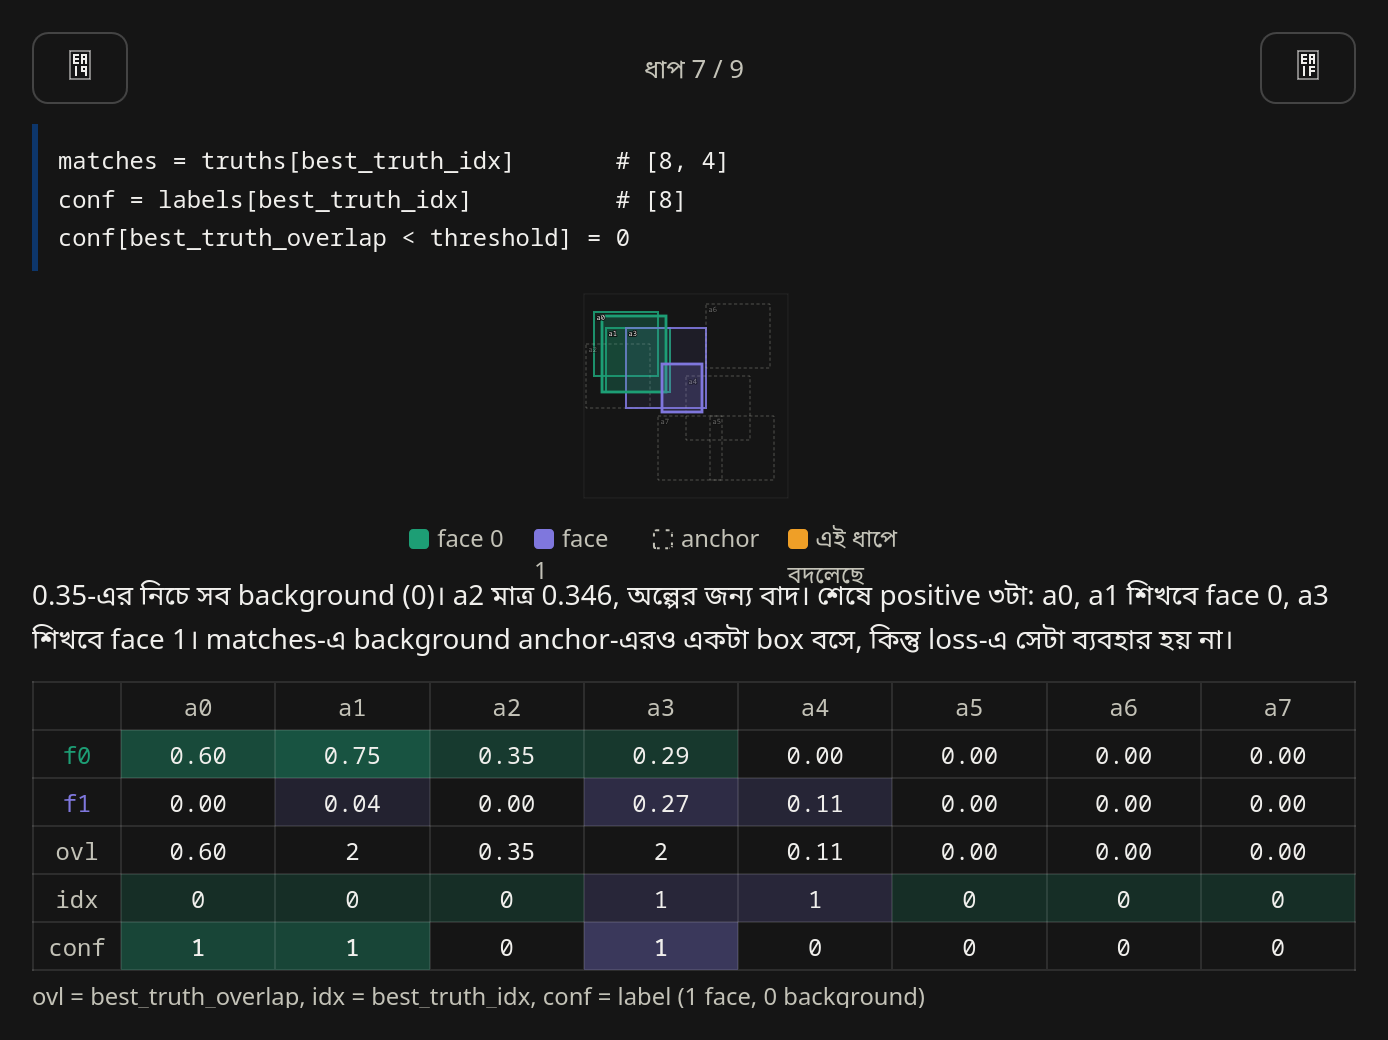



ix) In, previous step, how get the conf =1, if best_truth_overlap>0.35, here, we take those images.
and send them into a encode funtion. Where, positive anchor learns how must to adjust the anchor box 
to match the ground truth box. encode() calculate this. 




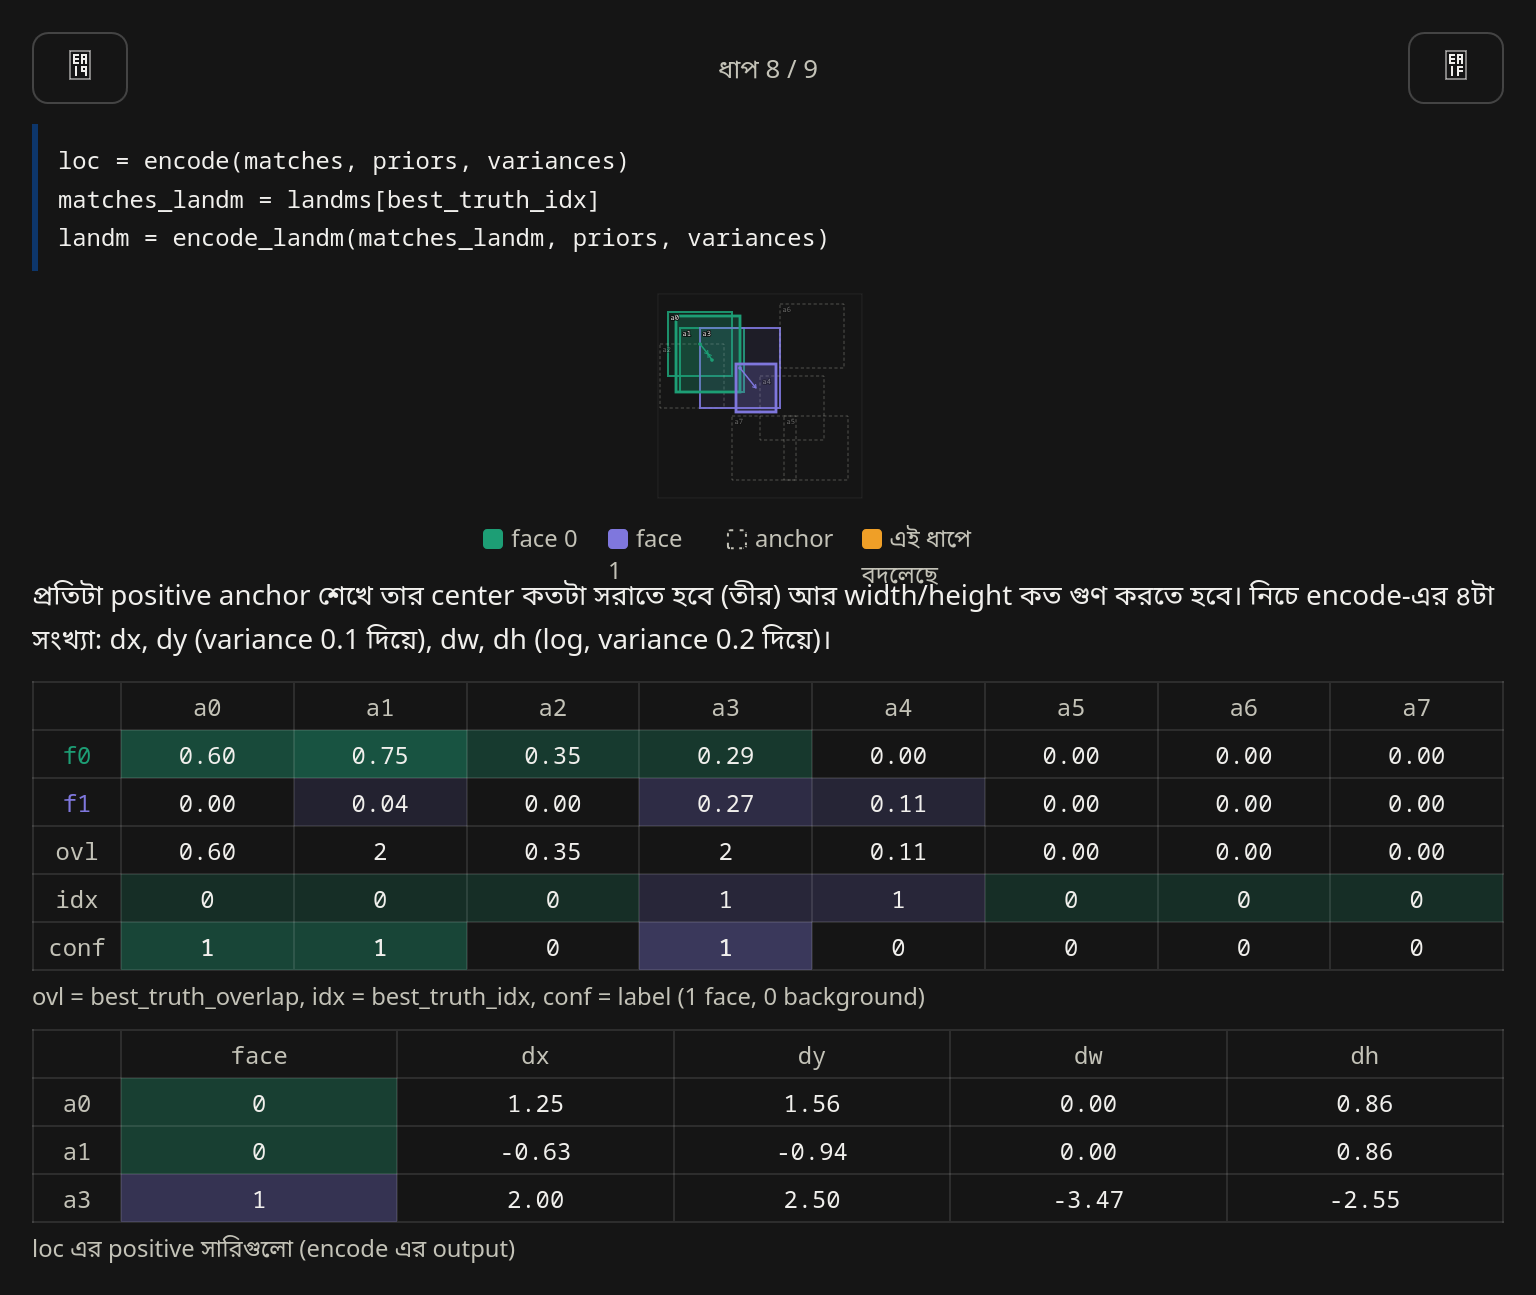



x) All the things does not return, it goes to the for BoxLoss.




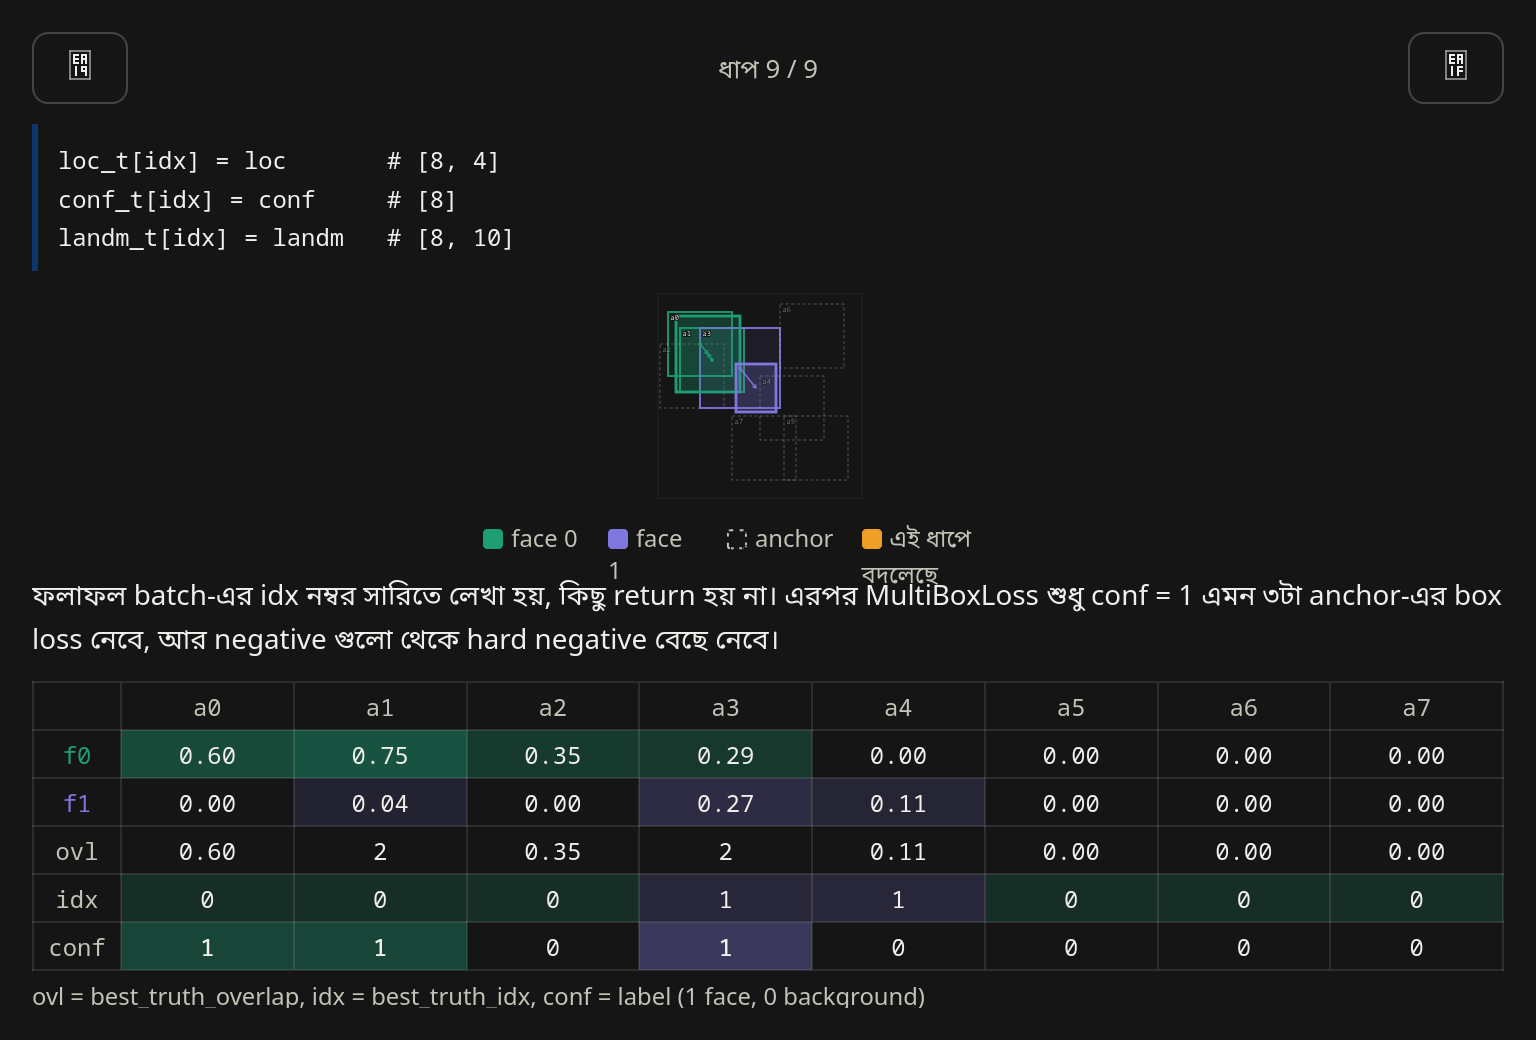

In [25]:

print(""" 
    
i) Here, at, first there are only one boxes that capture the man and the car. But there should be 
two bounding boxes. 

ii) To, sovle this type of problelm, first we assume there are so many anchor boxes. For the below example 
we take only two boxes.
    
"""
)
display(Image("../note/photo/image30.png"))

print("""
       
iii) In the code, for understanding, we assume that our ground truth value contains 2 face(truths) and 
we assume there are two anchor boxes.
      
"""
)

display(Image("../note/photo/image31.png"))

print("""
      
iv) Then we find which, anchor points IoU is to our truth value. IoU return a table like below.

""")

display(Image("../note/photo/image32.png"))


print("""
      
v) In, the code we do max(to find the best prior on the column.)

""")

display(Image("../note/photo/image33.png"))


print("""
      
vi) There is a hard theshold, 0.2 if IoU value is less then 0.2 then the ignore them.
""")

display(Image("../note/photo/image34.png"))


print("""
      
vii) Then here we find row wise max value with their indices.
""")

display(Image("../note/photo/image35.png"))


print("""
      
vii) Replace the value, of anchor1->index and anchor3->index:

""")

display(Image("../note/photo/image36.png"))

print("""
      
vii) While doing row wise maximum, our anchor-3 taken by the face-0. But, the prior said that
maybe it's face-1. So, our loop modify this. 

""")

display(Image("../note/photo/image37.png"))


print("""
      
viii) Now, based on our theshold, we find the confidance score. if confidence<0.35, 
then, mark it background. 

""")

display(Image("../note/photo/image38.png"))


print("""
      
ix) In, previous step, how get the conf =1, if best_truth_overlap>0.35, here, we take those images.
and send them into a encode funtion. Where, positive anchor learns how must to adjust the anchor box 
to match the ground truth box. encode() calculate this. 

""")

display(Image("../note/photo/image39.png"))

print("""
      
x) All the things does not return, it goes to the for BoxLoss.

""")

display(Image("../note/photo/image40.png"))




<br>
<br>

# Code implementation: 

<br>
<br>

In [ ]:
import torch 
import numpy as np 


def intersect(box_a, box_b):
    """ We resize both tensors to [A,B,2] without new malloc:
    [A,2] -> [A,1,2] -> [A,B,2]
    [B,2] -> [1,B,2] -> [A,B,2]
    Then we compute the area of intersect between box_a and box_b.
    Args:
      box_a: (tensor) bounding boxes, Shape: [A,4].
      box_b: (tensor) bounding boxes, Shape: [B,4].
    Return:
      (tensor) intersection area, Shape: [A,B].
    """
    # Input: A[[10,10,50,50]] B[[35,20,80,65]]->size(1,4)
    A = box_a.size(0) #1
    B = box_b.size(0) #1
    
    # torch.min -> [min(50,80), min(50,65)] = [[[50, 50]]]
    max_xy = torch.min(# [50,50] -> [[[50,50]]]  #(1,1,2) -> (pointA,pointB,total_2_point) -> 3D
                       box_a[:, 2:].unsqueeze(1).expand(A, B, 2),
                       box_b[:, 2:].unsqueeze(0).expand(A, B, 2))
    
    # torch.max -> [max(10,35), max(10,20)] = [[[35, 20]]]
    min_xy = torch.max( # [10,10] ->[[[10,10]]] # (1,1,2)
                       box_a[:, :2].unsqueeze(1).expand(A, B, 2),
                       box_b[:, :2].unsqueeze(0).expand(A, B, 2))
    
    # max_xy - min_xy = [50-35, 50-20] = [[[15, 30]]]
    # if any ans <0 then, that will be zero
    inter = torch.clamp((max_xy - min_xy), min=0)
    # [[15]]*[[30]] = [[450]] -> shape (1,1)
    return inter[:, :, 0] * inter[:, :, 1]


# orginal jaccard:
def iou_tensor(box_a, box_b):
    """Compute the box_iou_tensor overlap of two sets of boxes.  The box_iou_tensor overlap
    is simply the intersection over union of two boxes.  Here we operate on
    ground truth boxes and default boxes.
    E.g.:
        A ∩ B / A ∪ B = A ∩ B / (area(A) + area(B) - A ∩ B)
    Args:
        box_a: (tensor) Ground truth bounding boxes, Shape: [num_objects,4]
        box_b: (tensor) Prior boxes from priorbox layers, Shape: [num_priors,4]
    Return:
        box_iou_tensor overlap: (tensor) Shape: [box_a.size(0), box_b.size(0)]
    """
    inter = intersect(box_a, box_b)
    
    
    area_a = ((box_a[:, 2]-box_a[:, 0]) *
              (box_a[:, 3]-box_a[:, 1])).unsqueeze(1).expand_as(inter)  # [A,B]
    area_b = ((box_b[:, 2]-box_b[:, 0]) *
              (box_b[:, 3]-box_b[:, 1])).unsqueeze(0).expand_as(inter)  # [A,B]
    union = area_a + area_b - inter
    # output: 2 dim
    return inter / union  # [A,B]


def point_form(boxes):
    """ Convert prior_boxes to (xmin, ymin, xmax, ymax)
    representation for comparison to point form ground truth data.
    Args:
        boxes: (tensor) center-size default boxes from priorbox layers.
    Return:
        boxes: (tensor) Converted xmin, ymin, xmax, ymax form of boxes.
    """
    return torch.cat((boxes[:, :2] - boxes[:, 2:]/2,     # xmin, ymin
                     boxes[:, :2] + boxes[:, 2:]/2), 1)  # xmax, ymax


def center_size(boxes):
    """ Convert prior_boxes to (cx, cy, w, h)
    representation for comparison to center-size form ground truth data.
    Args:
        boxes: (tensor) point_form boxes
    Return:
        boxes: (tensor) Converted xmin, ymin, xmax, ymax form of boxes.
    """
    return torch.cat((boxes[:, 2:] + boxes[:, :2])/2,  # cx, cy
                     boxes[:, 2:] - boxes[:, :2], 1)  # w, h

def encode(matched, priors, variances):
    """Encode the variances from the priorbox layers into the ground truth boxes
    we have matched (based on jaccard overlap) with the prior boxes.
    Args:
        matched: (tensor) Coords of ground truth for each prior in point-form
            Shape: [num_priors, 4].
        priors: (tensor) Prior boxes in center-offset form
            Shape: [num_priors,4].
        variances: (list[float]) Variances of priorboxes
    Return:
        encoded boxes (tensor), Shape: [num_priors, 4]
    """

    # dist b/t match center and prior's center
    g_cxcy = (matched[:, :2] + matched[:, 2:])/2 - priors[:, :2]
    # encode variance
    g_cxcy /= (variances[0] * priors[:, 2:])
    # match wh / prior wh
    g_wh = (matched[:, 2:] - matched[:, :2]) / priors[:, 2:]
    g_wh = torch.log(g_wh) / variances[1]
    # return target for smooth_l1_loss
    return torch.cat([g_cxcy, g_wh], 1)  # [num_priors,4]

def encode_landm(matched, priors, variances):
    """Encode the variances from the priorbox layers into the ground truth boxes
    we have matched (based on jaccard overlap) with the prior boxes.
    Args:
        matched: (tensor) Coords of ground truth for each prior in point-form
            Shape: [num_priors, 10].
        priors: (tensor) Prior boxes in center-offset form
            Shape: [num_priors,4].
        variances: (list[float]) Variances of priorboxes
    Return:
        encoded landm (tensor), Shape: [num_priors, 10]
    """

    # dist b/t match center and prior's center
    matched = torch.reshape(matched, (matched.size(0), 5, 2))
    priors_cx = priors[:, 0].unsqueeze(1).expand(matched.size(0), 5).unsqueeze(2)
    priors_cy = priors[:, 1].unsqueeze(1).expand(matched.size(0), 5).unsqueeze(2)
    priors_w = priors[:, 2].unsqueeze(1).expand(matched.size(0), 5).unsqueeze(2)
    priors_h = priors[:, 3].unsqueeze(1).expand(matched.size(0), 5).unsqueeze(2)
    priors = torch.cat([priors_cx, priors_cy, priors_w, priors_h], dim=2)
    g_cxcy = matched[:, :, :2] - priors[:, :, :2]
    # encode variance
    g_cxcy /= (variances[0] * priors[:, :, 2:])
    # g_cxcy /= priors[:, :, 2:]
    g_cxcy = g_cxcy.reshape(g_cxcy.size(0), -1)
    # return target for smooth_l1_loss
    return g_cxcy

def match(threshold, truths, priors, variances, labels, landms, loc_t, conf_t, landm_t, idx):
    """Match each prior box with the ground truth box of the highest iou
    overlap, encode the bounding boxes, then return the matched indices
    corresponding to both confidence and location preds.
    Args:
        threshold: (float) The overlap threshold used when mathing boxes.
        truths: (tensor) Ground truth boxes, Shape: [num_obj, 4].
        priors: (tensor) Prior boxes from priorbox layers, Shape: [n_priors,4].
        variances: (tensor) Variances corresponding to each prior coord,
            Shape: [num_priors, 4].
        labels: (tensor) All the class labels for the image, Shape: [num_obj].
        landms: (tensor) Ground truth landms, Shape [num_obj, 10].
        loc_t: (tensor) Tensor to be filled w/ endcoded location targets.
        conf_t: (tensor) Tensor to be filled w/ matched indices for conf preds.
        landm_t: (tensor) Tensor to be filled w/ endcoded landm targets.
        idx: (int) current batch index
    Return:
        The matched indices corresponding to 1)location 2)confidence 3)landm preds.
    """
    # truths = two face:
    # anchor = 8 boxes.
    #"""
    #overlaps  (shape [2, 8])
    #          dim 1 (anchor) →
    #              a0    a1    a2    a3    a4    a5  a6  a7
    #dim 0  f0  [ 0.60  0.75  0.35  0.29  0.00  0   0   0 ]
    #(face) f1  [ 0.00  0.04  0.00  0.27  0.11  0   0   0 ]
    #↓
    #"""
    overlaps = iou_tensor(
        truths,
        point_form(priors)
    )

    # (Bipartite Matching)
    # [1,num_objects] best prior for each ground truth
    #  [[0.75], [0.27]] <-> Index([0], [1])
    # dim=1 means the second dimension, which is the number of columns in the tensor.
    best_prior_overlap, best_prior_idx = overlaps.max(1, keepdim=True)

    # ignore hard gt
    # if prior iou value < 0.2 then ignore: 
    valid_gt_idx = best_prior_overlap[:, 0] >= 0.2
    # [0.75(a1), 0.27(a3)] both are valid, so valid_gt_idx = [True, False]
    best_prior_idx_filter = best_prior_idx[valid_gt_idx, :]
    if best_prior_idx_filter.shape[0] <= 0:
        loc_t[idx] = 0
        conf_t[idx] = 0
        return

    # [1,num_priors] best ground truth for each prior, dim=0 row wise,
    #  best_truth_overlap = [0.75, 0.27, 0.35, 0.29, 0.11, 0, 0, 0]
    #  best_truth_idx = [0, 0, 0, 0, 1, 0, 0, 0]: 0-> face zero, 1-> face one
    best_truth_overlap, best_truth_idx = overlaps.max(0, keepdim=True)
    best_truth_idx.squeeze_(0)
    best_truth_overlap.squeeze_(0)
    best_prior_idx.squeeze_(1)
    best_prior_idx_filter.squeeze_(1)
    best_prior_overlap.squeeze_(1)

    # replace the value:  [0.75(a1), 0.27(a3)] -> [2, 2] 
    best_truth_overlap.index_fill_(0, best_prior_idx_filter, 2)  # ensure best prior

    # TODO refactor: index  best_prior_idx with long tensor
    # ensure every gt matches with its prior of max overlap
    #  best_truth_idx = [0, 0, 0, 0, 1, 0, 0, 0] modify this into:
    #  [0, 0, 0, 1, 1, 0, 0, 0] cause best_prior_idx for face-1 is anchor-3
    for j in range(best_prior_idx.size(0)):    
        best_truth_idx[best_prior_idx[j]] = j

    # find the matched ground truth.
    matches = truths[best_truth_idx]           
    conf = labels[best_truth_idx]   

    # best_truth_overlap[0.6,2,0.35,2,0.11,0,0,0]
    # IoU <= 0.35 identify as background, so set conf = 0 
    conf[best_truth_overlap < threshold] = 0  

    # box offset of each anchor to match the ground truth.
    # return [dx(from center how must shift left or right),dy(up down),dw(zoom width),dh(zoom height)] 
    # It's calculate for all priors, but only positive anchors will be used in loss function(BoxLoss).
    loc = encode(matches, priors, variances)

    # We have  5 landmarks in each face, for the positive anchors, we calucate how much we need 
    # to shift so that we can close to the 5 landsmarks. And this goes into BoxLoss funtion.
    # output: shape [P,10] -> 5 points.(x,y)
    matches_landm = landms[best_truth_idx]
    landm = encode_landm(matches_landm, priors, variances)

    # all those things for the BoxLoss Function.
    loc_t[idx] = loc   # [P, 4]   box offset target
    # in conf: 1-> face, 0-> background. This is not retured cause 
    # we sent it to MultiBoxLoss() funtion.
    conf_t[idx] = conf 
    landm_t[idx] = landm
    
    